# LABS-12: Value

In this lab we will explore and observe how a model performs over different classes using our kNN model that we built in the Analytics lab. We will be using the Fairlearn package to calculate various metrics to help us understand how our model performs across different classes.

Check out their [user guide](https://fairlearn.org/v0.10/user_guide/fairness_in_machine_learning.html) for more information on the package!

Run the notebook using the course environment. In its terminal, install fairlearn and save the environment with `pip freeze > requirements.txt`.

In [1]:
import fairlearn
print("Fairlearn version:", fairlearn.__version__)

Fairlearn version: 0.13.0


In [2]:
# import packages

import pandas as pd #data ingestion & cleaning
import numpy as np #numbers

# modeling
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Fairness metrics
import fairlearn.metrics
from fairlearn.metrics import MetricFrame
from fairlearn.metrics import count, true_positive_rate, false_positive_rate, selection_rate, demographic_parity_ratio

# visualization
import matplotlib.pyplot as plt

## Recreate the model
Rebuild the kNN model from LABS-10 Analytics using the cleaned data, score cutoff of 70, and selected k=9.

### Read in the data
Read the cleaned CSV exported by LABS-10 from `data/processed/`. Its high/low labels use a cutoff of 70.

In [3]:
model_data = pd.read_csv("data/processed/imdb_movies_cleaned.csv")
assert len(model_data) == 10052
assert model_data['score'].value_counts().to_dict() == {'low': 7184, 'high': 2868}
print('Cleaned rows:', len(model_data))
print(model_data['score'].value_counts())

Cleaned rows: 10052
score
low     7184
high    2868
Name: count, dtype: int64


For the FairLearn package, the target variable must be coded as 0/1.

In [4]:
# Recode 'score' as 0 (low) or 1 (high)
model_data['score'] = model_data['score'].map({'low': 0, 'high': 1})
assert model_data['score'].notna().all()
print('Positive class: high = 1; low = 0')

Positive class: high = 1; low = 0


### Seperate features from target

In [5]:
# features: all columns except 'score'
features = model_data.drop('score', axis=1)

# Target: score column
target = model_data['score']

### Dummy variables

In [6]:
## create dummy variables for the features dataframe
features = pd.get_dummies(features)

# preview the new features dataframe
features.head()

,budget_x,revenue,year,country_AU,country_ES,country_FR,country_GB,country_HK,country_IT,country_JP,...,top_lang_ Norwegian,top_lang_ Polish,top_lang_ Portuguese,top_lang_ Russian,top_lang_ Spanish,top_lang_ Swedish,top_lang_ Tagalog,top_lang_ Thai,top_lang_ Turkish,top_lang_other
0,0.163043,0.092901,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1.000000,0.792417,0.991667,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0.217391,0.247788,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,0.026739,0.011697,1.000000,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,0.167391,0.116613,1.000000,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Train/Test split

In [7]:
# train test split
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, random_state=45)


### Model: Build, Train, Test, and Evaluate
Use k=9, the value selected in LABS-10.

In [8]:
# Create the model
knn = KNeighborsClassifier(n_neighbors=9)  # selected in LABS-10

# Train the model
knn.fit(features_train, target_train)

# Test the model
target_predicted = knn.predict(features_test)

# Evaluate the model
print("Accuracy:", accuracy_score(target_test, target_predicted))

Accuracy: 0.748881153654898


In [9]:
## Print out the data to use below
model_data.head()

,score,budget_x,revenue,country,top_genre,top_lang,year
0,1,0.163043,0.092901,AU,Drama,English,1.000000
1,1,1.000000,0.792417,AU,Science Fiction,English,0.991667
2,1,0.217391,0.247788,AU,Animation,English,1.000000
3,0,0.026739,0.011697,AU,Animation,Spanish,1.000000
4,0,0.167391,0.116613,US,Action,English,1.000000


## Look at the Data for each category

Type the name of the category you'd like to explore in the quotes below. Be sure to use the exact name (case sensitive!) of the column from the data frame above.

> Use this information to answer **question 2**.


country:
country
AU       4880
US       2716
other     709
JP        502
KR        358
FR        219
GB        172
ES        151
IT        123
HK        120
MX        102

top_genre:
top_genre
Drama              1865
Action             1563
Comedy             1377
Horror              931
Animation           885
Thriller            577
Adventure           571
Romance             413
Crime               371
Family              333
Science Fiction     313
Fantasy             263
Documentary         176
Mystery             108
War                  77
Music                76
Western              72
History              46
TV Movie             35

top_lang:
top_lang
 English       7381
 Japanese       675
 Spanish        388
 Korean         384
 French         282
 Chinese        144
 Italian        142
 Cantonese      141
 German          89
other            72
 Russian         65
 Tagalog         42
 Portuguese      35
 Thai            33
 Norwegian       29
 Polish          26
 Hindi    

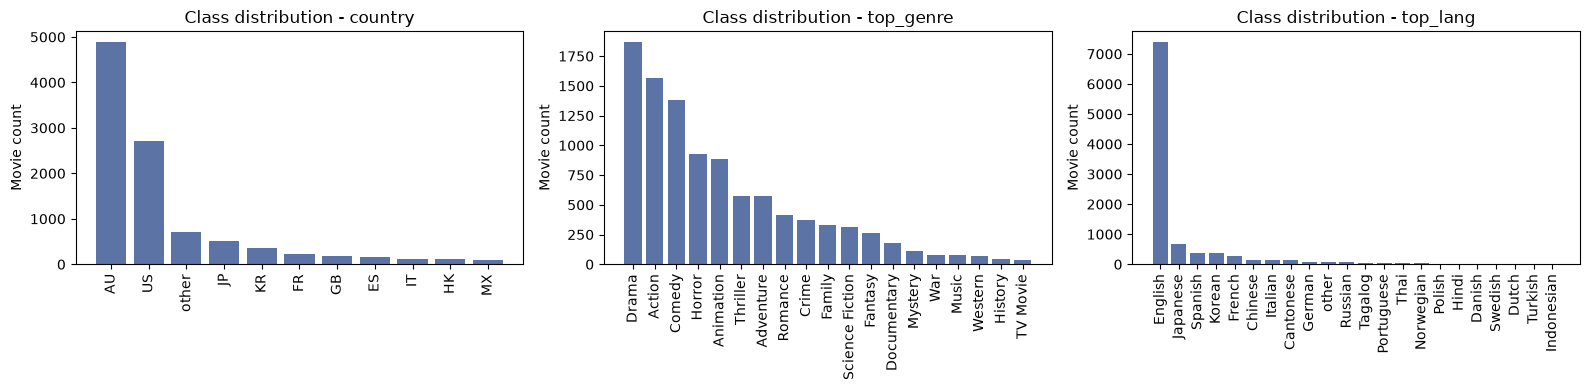

In [10]:
# Check representation in the full cleaned dataset for all three categories.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, category in zip(axes, ['country', 'top_genre', 'top_lang']):
    counts = model_data[category].value_counts()
    print(f'\n{category}:')
    print(counts.to_string())
    ax.bar(counts.index.astype(str).str.strip(), counts.values, color='#5B74A5')
    ax.set_title(f'Class distribution - {category}')
    ax.set_ylabel('Movie count')
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

## Fairness Metrics

We are using the Fairlearn package in Python.

You will need to understand what the metrics used below mean and how they are calculated. You can find information on the functions used in their documentation: https://fairlearn.org/v0.10/api_reference/index.html#module-fairlearn.metrics

In [11]:
# Construct a function dictionary with the metrics we'd like for each category
my_metrics = {
    'true positive rate' : true_positive_rate,
    'false positive rate' : false_positive_rate,
    'selection rate' : selection_rate,
    'count' : count
}
# Construct a MetricFrame for country
mf_country = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["country_AU"]
)

# Construct a MetricFrame for top_lang
mf_lang = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["top_lang_ English"]
)

# Construct a MetricFrame for top_genre
mf_genre = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["top_genre_Drama"]
)

In [12]:
def create_confmatrix(target_test, target_predicted):
    '''
    creates a confusion matrix with more descriptive formatting
    '''
    tn, fp, fn, tp = confusion_matrix(target_test, target_predicted, labels=[0, 1]).ravel() # grab the individual values

    # create a data frame with the values in the correct spots
    conf_matrix = pd.DataFrame({'predicted positive': [tp, fp],
                                'predicted negative': [fn, tn]},
                                index=['actual positive','actual negative'])

    # return the dataframe to be saved/viewed
    return conf_matrix

### Overall metrics

Here is the confusion matrix for the model overall with *counts* for the true positive, false positive, true negative, and false negative.

For more information on confusion matrices, check out the wiki page: https://en.wikipedia.org/wiki/Confusion_matrix

> Use this information to answer **quesiton 4**.

In [13]:
# overall confusion matrix
print("Confusion matrix for all test data:")
create_confmatrix(target_test, target_predicted)

Confusion matrix for all test data:


,predicted positive,predicted negative
actual positive,221,358
actual negative,147,1285


In [14]:
## The overall metrics. You'll use these to compare to with the metrics broken down by each category below.
## Think about how the differing performance would impact that group based on your understanding of each metric.
pd.DataFrame(mf_country.overall, columns = ["overall"]).T

,true positive rate,false positive rate,selection rate,count
overall,0.381693,0.102654,0.182994,2011.0


### Metrics by category

Here we are comparing the most prevalent class in each category to the rest of the categories.

> Use this information to answer **questions 5 & 6**.

#### `country`

The most prevalent country value is "AU". We will compare the model performance for the most prevalent country to the performance on the rest of the countries.

In [15]:
## metrics broken down by country classes. Compare these to the metrics above.
mf_country.by_group

,true positive rate,false positive rate,selection rate,count
country_AU,,,,
False,0.29249,0.081794,0.13452,1011.0
True,0.45092,0.126113,0.23200,1000.0


In [16]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_country = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["country_AU"])
print("Demographic Parity ratio:\t", dpr_country)

eodds_country = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["country_AU"])
print("Equalized Odds ratio:\t\t", eodds_country)

Demographic Parity ratio:	 0.5798287799720317


Equalized Odds ratio:		 0.6485798541052306


#### `top_lang`


The most prevalent language value is "English". We will compare the model performance for the most prevalent language to the performance on the rest of the languages.

In [17]:
## metrics broken down by top_lang classes. Compare these to the metrics above.

mf_lang.by_group

,true positive rate,false positive rate,selection rate,count
top_lang_ English,,,,
False,0.427807,0.176301,0.264540,533.0
True,0.359694,0.079190,0.153586,1478.0


In [18]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_lang = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["top_lang_ English"])
print("Demographic Parity ratio:\t", dpr_lang)

eodds_lang = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["top_lang_ English"])
print("Equalized Odds ratio:\t\t", eodds_lang)

Demographic Parity ratio:	 0.580576589026766


Equalized Odds ratio:		 0.4491742897684389


#### `top_genre`


The most prevalent genre value is "Drama". We will compare the model performance for the most prevalent genre to the performance on the rest of the genres.

In [19]:
## metrics broken down by top_genre classes. Compare these to the metrics above.

mf_genre.by_group

,true positive rate,false positive rate,selection rate,count
top_genre_Drama,,,,
False,0.354369,0.090538,0.156899,1638.0
True,0.449102,0.174757,0.297587,373.0


In [20]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_genre = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["top_genre_Drama"])
print("Demographic Parity ratio:\t", dpr_genre)

eodds_genre = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["top_genre_Drama"])
print("Equalized Odds ratio:\t\t", eodds_genre)

Demographic Parity ratio:	 0.5272360272360272
Equalized Odds ratio:		 0.5180804785209353


### Results summary
Rates below use the held-out test set. Representation counts use the full cleaned dataset. Each fairness comparison is the largest group versus all remaining groups combined.

In [21]:
from pathlib import Path
import json

summary_rows = []
fairness_rows = []
for category, largest, mf, indicator in [
    ('country', 'AU', mf_country, features_test['country_AU']),
    ('top_genre', 'Drama', mf_genre, features_test['top_genre_Drama']),
    ('top_lang', 'English', mf_lang, features_test['top_lang_ English'])
]:
    for selected, label in [(True, largest), (False, 'all others')]:
        values = mf.by_group.loc[selected]
        summary_rows.append({'category': category, 'group': label,
                             **{key: float(value) for key, value in values.items()}})
    fairness_rows.append({'category': category,
        'demographic parity ratio': fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=indicator),
        'equalized odds ratio': fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=indicator)})

groups = pd.DataFrame(summary_rows)
fairness_summary = pd.DataFrame(fairness_rows)
print(groups.to_string(index=False))
print(fairness_summary.to_string(index=False))
tn, fp, fn, tp = confusion_matrix(target_test, target_predicted, labels=[0, 1]).ravel()
summary = {'k': 9, 'cutoff': 70, 'accuracy': float(accuracy_score(target_test, target_predicted)),
 'overall': {key: float(value) for key, value in mf_country.overall.items()},
 'confusion': {'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn)},
 'groups': summary_rows, 'fairness': fairness_rows,
 'representation': {category: {str(key): int(value) for key, value in model_data[category].value_counts().items()}
                    for category in ['country', 'top_genre', 'top_lang']}}
Path('data/processed').mkdir(parents=True, exist_ok=True)
with open('data/processed/lab12_metrics.json', 'w') as file:
    json.dump(summary, file, indent=2)
groups.to_csv('data/processed/lab12_group_metrics.csv', index=False)
fairness_summary.to_csv('data/processed/lab12_fairness_ratios.csv', index=False)


 category      group  true positive rate  false positive rate  selection rate  count
  country         AU            0.450920             0.126113        0.232000 1000.0
  country all others            0.292490             0.081794        0.134520 1011.0
top_genre      Drama            0.449102             0.174757        0.297587  373.0
top_genre all others            0.354369             0.090538        0.156899 1638.0
 top_lang    English            0.359694             0.079190        0.153586 1478.0
 top_lang all others            0.427807             0.176301        0.264540  533.0
 category  demographic parity ratio  equalized odds ratio
  country                  0.579829              0.648580
top_genre                  0.527236              0.518080
 top_lang                  0.580577              0.449174


### Fairness metric question
Example exchange with Codex

**Question:** can demographic parity look good but equalized odds still be bad?

**Codex response:** Yes. Demographic parity only checks how often each group gets a high prediction. Equalized odds also checks whether the model catches actual high scores and how often it wrongly labels low scores as high. Two groups can get selected equally often while the model makes different mistakes for each group, so equal selection rates alone do not mean equal error rates.

**Verification:** DPR only uses selection rates, while EOR uses TPR and FPR. The language comparison has DPR 0.581 and EOR 0.449. Both show gaps here, but the formulas and results confirm that they check different things.
